<a href="https://colab.research.google.com/github/202618064-dau/ML-Project-Msc-DS-605/blob/main/ML_Proj_MAIN_NB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

df = pd.read_csv('raw_master_battery_features.csv')

df.replace([np.inf, -np.inf], np.nan, inplace=True)

print("Missing values per column:\n", df.isna().sum()[df.isna().sum() > 0])

numeric_cols = df.select_dtypes(include=[np.number]).columns
df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())

Missing values per column:
 Series([], dtype: int64)


# Feature Selection


Correlation with Target:
 log_cycle_life     1.000000
cycle_life         0.958364
mean_delta_Q       0.845271
min_temp           0.596160
qd_slope           0.432886
qd_diff_100_2      0.424538
ct_avg             0.288953
avg_temp           0.283722
temp_integral      0.283505
max_delta_Q        0.229976
ir_diff_100_2      0.223578
batch              0.199170
kurt_delta_Q       0.140750
ir_slope           0.081818
qd_max             0.012317
ct_slope          -0.094019
qd_intercept      -0.162122
max_temp          -0.251378
ir_min            -0.484861
ir_intercept      -0.495967
ir_mean           -0.507557
ir_max            -0.507982
skew_delta_Q      -0.528844
std_delta_Q       -0.880973
min_delta_Q       -0.892839
log_var_delta_Q   -0.895120
Name: log_cycle_life, dtype: float64


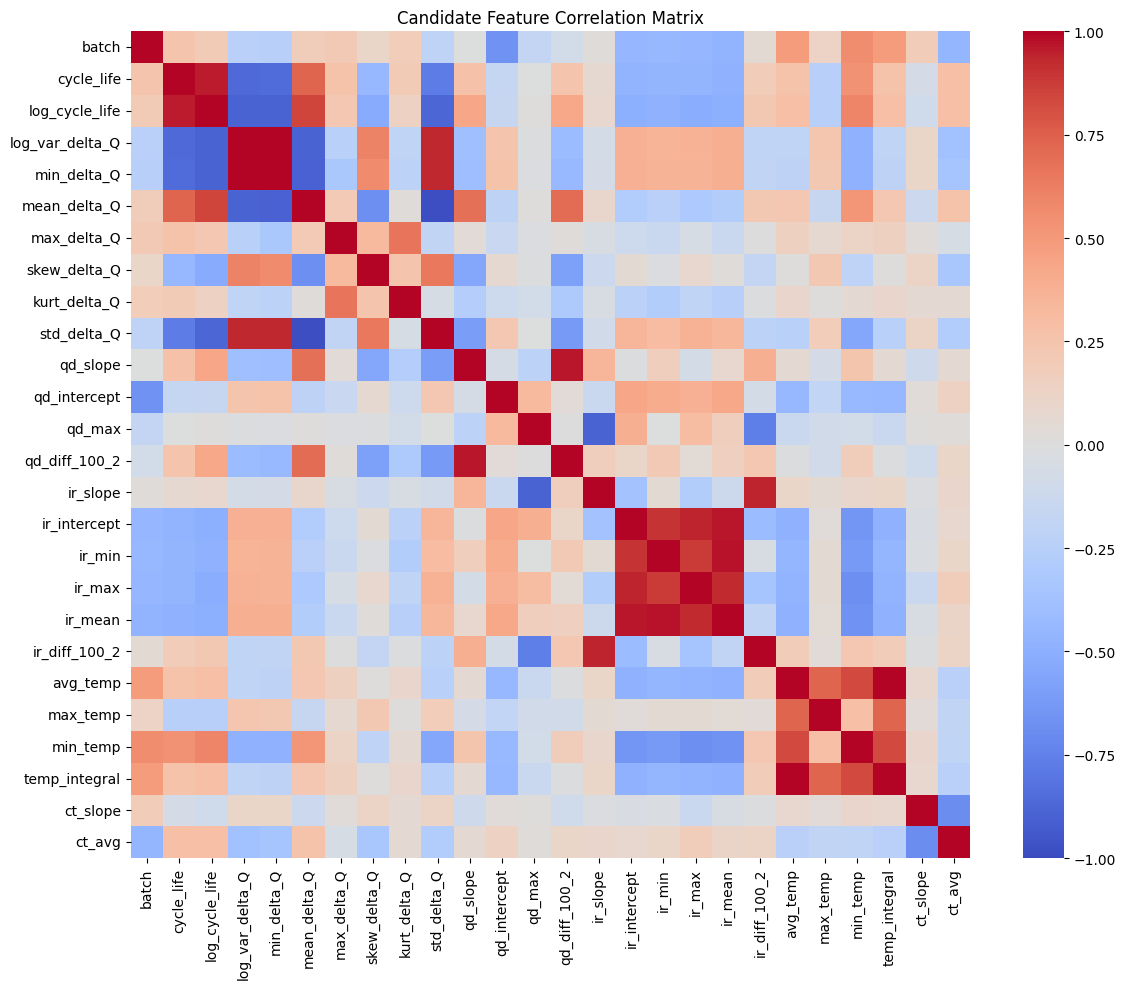

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

correlations = df[numeric_cols].corr()['log_cycle_life'].sort_values(ascending=False)
print("Correlation with Target:\n", correlations)

plt.figure(figsize=(12, 10))
sns.heatmap(df[numeric_cols].corr(), cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Candidate Feature Correlation Matrix")
plt.tight_layout()
plt.savefig('correlation_matrix.png')

In [ ]:
target_col = 'log_cycle_life'
metadata_cols = ['cell_id', 'batch', 'charge_policy', 'cycle_life', target_col]

y = df[target_col]
candidate_cols = [col for col in df.columns if col not in metadata_cols]
X_candidates = df[candidate_cols]

corr_matrix = X_candidates.corr().abs()
target_corr = X_candidates.apply(lambda col: abs(col.corr(y)))

threshold = 0.85
to_drop = set()

for i in range(len(candidate_cols)):
    for j in range(i + 1, len(candidate_cols)):
        col1 = candidate_cols[i]
        col2 = candidate_cols[j]

        if corr_matrix.loc[col1, col2] >= threshold:
            if target_corr[col1] < target_corr[col2]:
                to_drop.add(col1)
            else:
                to_drop.add(col2)

# Extract Final X Matrix
selected_features = [col for col in candidate_cols if col not in to_drop]

X = df[selected_features]

print(f"Initial candidate features count: {len(candidate_cols)}")
print(f"Features dropped due to collinearity (r >= {threshold}): {len(to_drop)}")
print(f"\nDropped features: {sorted(list(to_drop))}")
print(f"\nDynamically selected features ({len(selected_features)}): {selected_features}")
print(f"\nFinal feature matrix shape: X = {X.shape}, y = {y.shape}")

Initial candidate features count: 23
Features dropped due to collinearity (r >= 0.85): 10

Dropped features: ['ir_intercept', 'ir_mean', 'ir_min', 'ir_slope', 'mean_delta_Q', 'min_delta_Q', 'qd_diff_100_2', 'qd_max', 'std_delta_Q', 'temp_integral']

Dynamically selected features (13): ['log_var_delta_Q', 'max_delta_Q', 'skew_delta_Q', 'kurt_delta_Q', 'qd_slope', 'qd_intercept', 'ir_max', 'ir_diff_100_2', 'avg_temp', 'max_temp', 'min_temp', 'ct_slope', 'ct_avg']

Final feature matrix shape: X = (125, 13), y = (125,)


# Data Leakage & "Batch Memorization"

Why holdout method?

In [ ]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import StandardScaler

# Load cleaned feature matrix
df = pd.read_csv('raw_master_battery_features.csv')
features = ['log_var_delta_Q', 'min_delta_Q', 'ir_slope', 'ir_min', 'qd_slope', 'avg_temp']

X = StandardScaler().fit_transform(df[features])
y_batch = df['batch']

# Train a classifier to try and guess the batch no.
clf = RandomForestClassifier(random_state=42)
acc_scores = cross_val_score(clf, X, y_batch, cv=5, scoring='accuracy')

print(f"Batch Identification Accuracy: {acc_scores.mean() * 100:.2f}%")

Batch Identification Accuracy: 91.20%


# MODEL TRAINING

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

selected_features = [
    'log_var_delta_Q', 'max_delta_Q', 'skew_delta_Q', 'kurt_delta_Q',
    'qd_slope', 'qd_intercept', 'ir_max', 'ir_diff_100_2',
    'avg_temp', 'max_temp', 'min_temp', 'ct_slope', 'ct_avg'
]

train_mask = df['batch'].isin([1, 2])
test_mask = df['batch'] == 3

X_train = df.loc[train_mask, selected_features]
y_train_log = df.loc[train_mask, 'log_cycle_life']

X_test = df.loc[test_mask, selected_features]
y_test_log = df.loc[test_mask, 'log_cycle_life']
y_test_actual = df.loc[test_mask, 'cycle_life']

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Ridge Regression": Ridge(alpha=1.0),
    "Support Vector Regression (SVR)": SVR(C=1.0, epsilon=0.1),
    "XGBoost Regressor": XGBRegressor(max_depth=3, n_estimators=50, learning_rate=0.05, random_state=42)
}

print("Batch 3 Holdout Evaluation Results ")
results = []
for name, model in models.items():
    model.fit(X_train_scaled, y_train_log)
    preds_log = model.predict(X_test_scaled)

    # Transform target back from log10 space to real cycle counts (10^y)
    preds_cycles = 10**preds_log

    # Calculate performance metrics in actual cycle units
    rmse = np.sqrt(mean_squared_error(y_test_actual, preds_cycles))
    mae = mean_absolute_error(y_test_actual, preds_cycles)
    r2 = r2_score(y_test_actual, preds_cycles)
    mape = np.mean(np.abs((y_test_actual - preds_cycles) / y_test_actual)) * 100

    results.append({'Model': name, 'RMSE (cycles)': rmse, 'MAE (cycles)': mae, 'MAPE (%)': mape, 'R²': r2})

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

Batch 3 Holdout Evaluation Results 
                          Model  RMSE (cycles)  MAE (cycles)  MAPE (%)        R²
               Ridge Regression     323.421698    193.791614 15.916286 -0.154643
Support Vector Regression (SVR)     482.064228    383.302035 33.138951 -1.565189
              XGBoost Regressor     291.978385    181.456329 14.527795  0.058954
